In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn openpyxl jupyter streamlit joblib plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# SEWA Daily Peak Electricity Demand Forecasting System

## 1. Project Background

Electricity demand changes over time due to weather
conditions, human activities and other factors.
Understanding and predicting electricity demand is
important for electricity supply planning and
operational decision-making.

## 2. Problem Statement

In this project, I investigated how historical electricity
demand, weather conditions and calendar information
can be used to predict daily peak electricity load.

## 3. Project Objective

To develop a machine-learning model that predicts
daily peak electricity demand using the SEWA
electricity demand dataset for 2020 and 2021.

## 4. Prediction Target

SEWA Peak Load (MW).

## 5. Development Tools

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook
- Streamlit

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [3]:
file_path="../data/raw/SEWA Electricity Demand Forecasting_2020_2021.xlsx"

excel_file = pd.ExcelFile(file_path)

print(excel_file.sheet_names)

['2020 Load Distribution', ' Load 2020 hourly', '2021 Load Distribution', ' Load 2021 hourly']


In [4]:
print("Number of worksheets:", len(excel_file.sheet_names))

for sheet in excel_file.sheet_names:
  print(sheet)

Number of worksheets: 4
2020 Load Distribution
 Load 2020 hourly
2021 Load Distribution
 Load 2021 hourly


In [5]:
# Load the 2020 and 2021 daily datasets

df_2020 = pd.read_excel(
  file_path,
  sheet_name="2020 Load Distribution",
  header=2
)

df_2021 = pd.read_excel(
  file_path,
  sheet_name="2021 Load Distribution",
  header=2
)

In [6]:
print("2020 Dataset:")
display(df_2020.head())

print("2021 Dataset:")
display(df_2021.head())

2020 Dataset:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
0,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-01,2020-01-01,27,17,94,45,18.7,57.1,676.0,856.0,778.558333
2,2020-01-02,2020-01-02,27,16,90,45,20.0,36.0,673.0,971.0,831.135000
3,2020-01-03,2020-01-03,28,15,91,34,20.0,56.8,701.0,868.0,810.412500
4,2020-01-04,2020-01-04,30,15,80,23,20.0,33.0,712.0,1009.0,875.083333


2021 Dataset:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
0,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-01,2021-01-01,28.0,16.0,79.0,35.0,19.1,50.0,652.0,812.0,734.203333
2,2021-01-02,2021-01-02,27.9,14.4,76.0,21.0,19.0,41.5,643.0,936.0,802.082917
3,2021-01-03,2021-01-03,27.0,12.0,74.0,25.0,20.0,36.0,682.0,949.0,820.441667
4,2021-01-04,2021-01-04,27.0,12.0,73.0,14.0,17.0,16.0,653.0,942.0,801.066667


In [7]:
print("2020 Dataset Shape:", df_2020.shape)
print("2021 Dataset Shape:", df_2021.shape)

2020 Dataset Shape: (367, 11)
2021 Dataset Shape: (367, 11)


In [8]:
print("2020 Dataset Information:")
df_2020.info()

print("2021 Dataset Information:")
df_2021.info()

2020 Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                366 non-null    datetime64[us]
 1   Day                 366 non-null    datetime64[us]
 2   MAX Tem             365 non-null    object        
 3   Min Tem             365 non-null    object        
 4   Max Hum             365 non-null    object        
 5   Min Hum             365 non-null    object        
 6   Temp                366 non-null    float64       
 7   Hum                 366 non-null    float64       
 8   SEWA MIN LOAD(MW)   366 non-null    float64       
 9   SEWA Peak Load(MW)  366 non-null    float64       
 10  SEWA Enry./hr.      366 non-null    float64       
dtypes: datetime64[us](2), float64(5), object(4)
memory usage: 31.7+ KB
2021 Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 367 entries, 0 

In [9]:
print("2020 - First 5 rows")
display(df_2020.head())

print("2021 - First 5 rows")
display(df_2021.head())

print("2020 - Last 5 rows")
display(df_2020.tail())

print("2021 - Last 5 rows")
display(df_2021.tail())

2020 - First 5 rows


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
0,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-01,2020-01-01,27,17,94,45,18.7,57.1,676.0,856.0,778.558333
2,2020-01-02,2020-01-02,27,16,90,45,20.0,36.0,673.0,971.0,831.135000
3,2020-01-03,2020-01-03,28,15,91,34,20.0,56.8,701.0,868.0,810.412500
4,2020-01-04,2020-01-04,30,15,80,23,20.0,33.0,712.0,1009.0,875.083333


2021 - First 5 rows


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
0,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-01,2021-01-01,28.0,16.0,79.0,35.0,19.1,50.0,652.0,812.0,734.203333
2,2021-01-02,2021-01-02,27.9,14.4,76.0,21.0,19.0,41.5,643.0,936.0,802.082917
3,2021-01-03,2021-01-03,27.0,12.0,74.0,25.0,20.0,36.0,682.0,949.0,820.441667
4,2021-01-04,2021-01-04,27.0,12.0,73.0,14.0,17.0,16.0,653.0,942.0,801.066667


2020 - Last 5 rows


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
362,2020-12-27,2020-12-27,27,15,56,26,20.0,14.0,681.0,939.0,821.054167
363,2020-12-28,2020-12-28,1900-01-28 00:00:00,1900-01-14 00:00:00,1900-03-02 00:00:00,1900-01-24 00:00:00,19.0,22.0,660.0,950.0,821.758333
364,2020-12-29,2020-12-29,1900-01-27 02:24:00,1900-01-12 04:48:00,1900-03-18 00:00:00,1900-01-18 00:00:00,19.0,67.0,683.0,946.0,811.583333
365,2020-12-30,2020-12-30,1900-01-28 12:00:00,1900-01-13 00:00:00,1900-03-05 00:00:00,1900-01-31 00:00:00,18.0,56.0,660.0,962.0,816.000000
366,2020-12-31,2020-12-31,1900-01-29 00:00:00,1900-01-16 00:00:00,1900-03-15 00:00:00,1900-01-29 00:00:00,20.0,69.0,696.0,957.0,820.291667


2021 - Last 5 rows


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
362,2021-12-28,2021-12-28,26.0,15.0,83.0,40.0,20.0,57.0,817.0,1065.0,962.625
363,2021-12-29,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,822.0,1060.0,119.500
364,2021-12-30,2021-12-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
365,2021-12-31,2021-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
366,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


In [10]:
print("2020 Columns:")
print(df_2020.columns.tolist())

print("\n2021 Columns:")
print(df_2021.columns.tolist())

2020 Columns:
['Date', 'Day', 'MAX Tem', 'Min Tem', 'Max Hum', 'Min Hum', 'Temp', 'Hum', 'SEWA MIN LOAD(MW)', 'SEWA Peak Load(MW)', 'SEWA Enry./hr.']

2021 Columns:
['Date', 'Day', 'MAX Tem', 'Min Tem', 'Max Hum', 'Min Hum', 'Temp', 'Hum', 'SEWA MIN LOAD(MW)', 'SEWA Peak Load(MW)', 'SEWA Enry./hr.']


In [11]:
print("2020 Shape:", df_2020.shape)
print("2021 Shape:", df_2021.shape)

2020 Shape: (367, 11)
2021 Shape: (367, 11)


In [12]:
weather_columns = [
  "MAX Tem",
  "Min Tem",
  "Max Hum",
  "Min Hum"
]

print("2020 Weather Data Types:")
print(df_2020[weather_columns].dtypes)

print("\n2020 Last 10 Weather Records: ")
display(df_2020[["Date"] + weather_columns].tail(10))

2020 Weather Data Types:
MAX Tem    object
Min Tem    object
Max Hum    object
Min Hum    object
dtype: object

2020 Last 10 Weather Records: 


,Date,MAX Tem,Min Tem,Max Hum,Min Hum
357,2020-12-22,27,16,74,36
358,2020-12-23,28,14,79,26
359,2020-12-24,28,14,69,29
360,2020-12-25,27,17,69,43
361,2020-12-26,25,15,66,37
362,2020-12-27,27,15,56,26
363,2020-12-28,1900-01-28 00:00:00,1900-01-14 00:00:00,1900-03-02 00:00:00,1900-01-24 00:00:00
364,2020-12-29,1900-01-27 02:24:00,1900-01-12 04:48:00,1900-03-18 00:00:00,1900-01-18 00:00:00
365,2020-12-30,1900-01-28 12:00:00,1900-01-13 00:00:00,1900-03-05 00:00:00,1900-01-31 00:00:00
366,2020-12-31,1900-01-29 00:00:00,1900-01-16 00:00:00,1900-03-15 00:00:00,1900-01-29 00:00:00


In [13]:
print("2020 Weather Data Types:")
print(df_2021[weather_columns].dtypes)

print("\n2021 Last 10 Weather Records:")
display(df_2021[["Date"] + weather_columns].tail(10))

2020 Weather Data Types:
MAX Tem    float64
Min Tem    float64
Max Hum    float64
Min Hum    float64
dtype: object

2021 Last 10 Weather Records:


,Date,MAX Tem,Min Tem,Max Hum,Min Hum
357,2021-12-23,28.0,17.0,77.0,39.0
358,2021-12-24,27.9,18.4,76.0,40.0
359,2021-12-25,26.8,19.0,77.0,49.0
360,2021-12-26,27.0,20.0,74.0,43.0
361,2021-12-27,26.0,17.0,78.0,35.0
362,2021-12-28,26.0,15.0,83.0,40.0
363,2021-12-29,NaN,NaN,NaN,NaN
364,2021-12-30,NaN,NaN,NaN,NaN
365,2021-12-31,NaN,NaN,NaN,NaN
366,NaT,NaN,NaN,NaN,NaN


In [14]:
print("2020 MAX TEM values data types:")

print(
  df_2020["MAX Tem"]
  .apply(lambda x: type(x).__name__)
  .value_counts()
)

2020 MAX TEM values data types:
MAX Tem
int         258
float       105
datetime      4
Name: count, dtype: int64


In [15]:
print("2020 Completely Empty Rows:")
print(df_2020[df_2020.isnull().all(axis=1)])

print("\n2021 Completely Empty Rows:")
print(df_2021[df_2021.isnull().all(axis=1)])

2020 Completely Empty Rows:
  Date Day MAX Tem Min Tem Max Hum Min Hum  Temp  Hum  SEWA MIN LOAD(MW)  \
0  NaT NaT     NaN     NaN     NaN     NaN   NaN  NaN                NaN   

   SEWA Peak Load(MW)  SEWA Enry./hr.  
0                 NaN             NaN  

2021 Completely Empty Rows:
  Date Day  MAX Tem  Min Tem  Max Hum  Min Hum  Temp  Hum  SEWA MIN LOAD(MW)  \
0  NaT NaT      NaN      NaN      NaN      NaN   NaN  NaN                NaN   

   SEWA Peak Load(MW)  SEWA Enry./hr.  
0                 NaN             NaN  


In [16]:
df_2020.isnull().all(axis=1)

0       True
1      False
2      False
3      False
4      False
       ...  
362    False
363    False
364    False
365    False
366    False
Length: 367, dtype: bool

In [17]:
print("2020 Rows with Missing Dates:")
display(df_2020[df_2020["Date"].isnull()])

print("2021 Rows with missing Dates:")
display(df_2021[df_2021["Date"].isnull()])

2020 Rows with Missing Dates:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
0,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2021 Rows with missing Dates:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
0,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


In [18]:
print("2020 Zero Peak Load Rcords: ")
display(
  df_2020[df_2020["SEWA Peak Load(MW)"] == 0]
)

print("\n2021 Zero Peak Load Records: ")
display(
  df_2021[df_2021["SEWA Peak Load(MW)"] == 0]
)

2020 Zero Peak Load Rcords: 


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.



2021 Zero Peak Load Records: 


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
364,2021-12-30,2021-12-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
365,2021-12-31,2021-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
366,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


In [19]:
weather_columns = ["MAX Tem", "Min Tem", "Max Hum", "Min Hum"]

for column in weather_columns:
  print(f"\n2020 - {column}")
  print(df_2020[column]
        .apply(lambda x: type(x).__name__)
        .value_counts())


2020 - MAX Tem
MAX Tem
int         258
float       105
datetime      4
Name: count, dtype: int64

2020 - Min Tem
Min Tem
int         268
float        95
datetime      4
Name: count, dtype: int64

2020 - Max Hum
Max Hum
int         361
datetime      4
float         2
Name: count, dtype: int64

2020 - Min Hum
Min Hum
int         360
datetime      4
float         3
Name: count, dtype: int64


In [20]:
zero_peak_2021 = df_2021[
  df_2021["SEWA Peak Load(MW)"] == 0
]

display(
  zero_peak_2021[
    ["Date", "SEWA Peak Load(MW)", "SEWA MIN LOAD(MW)", "Temp", "Hum"]
  ]
)

,Date,SEWA Peak Load(MW),SEWA MIN LOAD(MW),Temp,Hum
364,2021-12-30,0.0,NaN,NaN,NaN
365,2021-12-31,0.0,NaN,NaN,NaN
366,NaT,0.0,NaN,NaN,NaN


# 2. Data Cleaning and Preparation

In this section, I will prepare the daily SEWA datasets
for exploratory data analysis and machine learning.

The original datasets will remain unchanged. All cleaning
operations will be performed on working copies.

In [21]:
# Working Copies
df_2020_clean = df_2020.copy()
df_2021_clean = df_2021.copy()

print("2020 working copy:", df_2020_clean.shape)
print("2021 working copy:", df_2021_clean.shape)

2020 working copy: (367, 11)
2021 working copy: (367, 11)


In [22]:
# Removed empty rows

df_2020_clean = df_2020_clean.dropna(how="all")
df_2021_clean = df_2021_clean.dropna(how="all")

print("2020 shape after removing empty rows:", df_2020_clean.shape)
print("2021 shape after removing empty rows:", df_2021_clean.shape)


2020 shape after removing empty rows: (366, 11)
2021 shape after removing empty rows: (366, 11)


In [23]:
print("2020 zero peak-load records: ", 
      (df_2020_clean["SEWA Peak Load(MW)"] == 0).sum())

print("2021 zero peak-load records:", 
      (df_2021_clean["SEWA Peak Load(MW)"] == 0).sum())

2020 zero peak-load records:  0
2021 zero peak-load records: 3


In [24]:
def recover_excel_serial_numbers(value):
  
  if isinstance(value, pd.Timestamp) and value.year == 1900:
    
    excel_serial = (
      value - pd.Timestamp("1899-12-30")
    ).total_seconds() / 86400
    
    # Correct for Excel's 1900 leap-year bug
    if value < pd.Timestamp("1900-03-01"):
      excel_serial -= 1
    return float(excel_serial)
  
  return pd.to_numeric(value, errors="coerce")

weather_cols = ["MAX Tem", "Min Tem", "Max Hum", "Min Hum"]

for col in weather_cols:
  df_2020_clean[col] = df_2020_clean[col].apply(recover_excel_serial_numbers)  
    

In [25]:
print("Recovered 2020 December weather values:")

display(
  df_2020_clean[
    ["Date"] + weather_cols
  ].tail(5)
)

Recovered 2020 December weather values:


,Date,MAX Tem,Min Tem,Max Hum,Min Hum
362,2020-12-27,27.0,15.0,56.0,26.0
363,2020-12-28,NaN,NaN,NaN,NaN
364,2020-12-29,NaN,NaN,NaN,NaN
365,2020-12-30,NaN,NaN,NaN,NaN
366,2020-12-31,NaN,NaN,NaN,NaN


In [26]:
df_2020_clean = df_2020.copy()

df_2020_clean = df_2020_clean.dropna(how="all")

In [27]:
from datetime import datetime, date

def recover_excel_serial_numbers(value):
  
  if isinstance(value, (pd.Timestamp, datetime, date)) and value.year == 1900:
    
    excel_serial = (
      pd.Timestamp(value) - pd.Timestamp("1899-12-30")
    ).total_seconds( ) / 86400
    
    # Correct Excel's 1900 leap-year bug
    
    if value < pd.Timestamp ("1900-03-01"):
      excel_serial -= 1
      
    return float(excel_serial)
    
  return pd.to_numeric(value, errors="coerce")

weather_cols = ["MAX Tem", "Min Tem", "Max Hum", "Min Hum"]

for col in weather_cols:
  df_2020_clean[col] = df_2020_clean[col].apply(
    recover_excel_serial_numbers
  )

In [28]:
display(
  df_2020_clean[
    ["Date"] + weather_cols
  ].tail(5)
)

,Date,MAX Tem,Min Tem,Max Hum,Min Hum
362,2020-12-27,27.0,15.0,56.0,26.0
363,2020-12-28,28.0,14.0,62.0,24.0
364,2020-12-29,27.1,12.2,78.0,18.0
365,2020-12-30,28.5,13.0,65.0,31.0
366,2020-12-31,29.0,16.0,75.0,29.0


In [29]:
print(df_2020_clean[weather_cols].dtypes)

MAX Tem    float64
Min Tem    float64
Max Hum    float64
Min Hum    float64
dtype: object


### Recovery of December 2020 Weather Measurements

Four weather columns contained values incorrectly
interpreted as Excel dates from 1900.

I recovered the underlying Excel serial numbers 
programmatically using Python. The recovery function
also accounted for Excel's 1900 leap-year date system.

All four columns were successfully converted to
numeric data types (float64).

The original dataset was preserved throughout the process.

In [30]:
df_2021_clean = df_2021_clean.dropna(subset=["Date"]).copy()

print("2021 shape after removing undated rows: ")
print(df_2021_clean.shape)

2021 shape after removing undated rows: 
(365, 11)


In [31]:
# Identify zero peak-load records

zero_peak_mask = df_2021_clean["SEWA Peak Load(MW)"] == 0

print("Number of zero-load records:", zero_peak_mask.sum())

display(
  df_2021_clean.loc[
    zero_peak_mask,
    ["Date", "SEWA Peak Load(MW)", "SEWA MIN LOAD(MW)", "Temp", "Hum"]
  ]
)

Number of zero-load records: 2


,Date,SEWA Peak Load(MW),SEWA MIN LOAD(MW),Temp,Hum
364,2021-12-30,0.0,NaN,NaN,NaN
365,2021-12-31,0.0,NaN,NaN,NaN


In [32]:
df_2021_clean.loc[
  zero_peak_mask,
  "SEWA Peak Load(MW)"
] = np.nan

In [33]:
print("2021 final working shape:", df_2021_clean.shape)

print("\nMissing peak-load values:")
print(df_2021_clean["SEWA Peak Load(MW)"].isnull().sum())

print("\nLast five records:")
display(df_2021_clean.tail())

2021 final working shape: (365, 11)

Missing peak-load values:
2

Last five records:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
361,2021-12-27,2021-12-27,26.0,17.0,78.0,35.0,24.2,32.0,862.0,1079.0,981.875
362,2021-12-28,2021-12-28,26.0,15.0,83.0,40.0,20.0,57.0,817.0,1065.0,962.625
363,2021-12-29,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,822.0,1060.0,119.500
364,2021-12-30,2021-12-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,2021-12-31,2021-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
# Sorting both datasets by date

df_2020_clean = df_2020_clean.sort_values("Date").copy()
df_2021_clean = df_2021_clean.sort_values("Date").copy()

#Removing records without valid target vaalues
df_2020_clean = df_2020_clean.dropna(
  subset=["SEWA Peak Load(MW)"]
).copy()

df_2021_clean = df_2021_clean.dropna(
  subset=["SEWA Peak Load(MW)"]
).copy()

In [35]:
weather_cols = [
  "MAX Tem", "Min Tem", "Max Hum", "Min Hum", "Temp", "Hum"
]

for col in weather_cols:
  df_2020_clean[col] = (
    df_2020_clean[col]
    .interpolate(
      method="linear",
      limit=1,
      limit_area="inside"
    )
  )
  
  df_2021_clean[col] = (
    df_2021_clean[col]
    .interpolate(
      method="linear",
      limit=1,
      limit_area="inside"
    )
  )

In [36]:
print("2020 Missing values:")
print(df_2020_clean[weather_cols + ["SEWA Peak Load(MW)"]].isnull().sum())

print("\n2021 Missiing values:")
print(df_2021_clean[weather_cols + ["SEWA Peak Load(MW)"]].isnull().sum())

2020 Missing values:
MAX Tem               0
Min Tem               0
Max Hum               0
Min Hum               0
Temp                  0
Hum                   0
SEWA Peak Load(MW)    0
dtype: int64

2021 Missiing values:
MAX Tem               1
Min Tem               1
Max Hum               1
Min Hum               1
Temp                  0
Hum                   0
SEWA Peak Load(MW)    0
dtype: int64


In [37]:
print("2020 Duplicate Dates:")
print(df_2020_clean["Date"].duplicated().sum())

print("\n2021 Duplicate Dates:")
print(df_2021_clean["Date"].duplicated().sum())

2020 Duplicate Dates:
0

2021 Duplicate Dates:
0


In [38]:
print("2020 Duplicate Records:")
display(
  df_2020_clean[
    df_2020_clean["Date"].duplicated(keep=False)
  ]
)

print("2021 Duplicate Records:")
display(
  df_2021_clean[
    df_2021_clean["Date"].duplicated(keep=False)
  ]
)

2020 Duplicate Records:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.


2021 Duplicate Records:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.


In [39]:
print("2020: Maximum temperature below minimum")
display(
  df_2020_clean[
    df_2020_clean['MAX Tem'] < df_2020_clean["Min Tem"]
  ][["Date", "MAX Tem", "Min Tem"]]
)

print("2021: Maximum temperature below minimum")
display(
  df_2021_clean[
    df_2021_clean["MAX Tem"] < df_2021_clean["Min Tem"]
  ][["Date", "MAX Tem", "Min Tem"]]
)

2020: Maximum temperature below minimum


,Date,MAX Tem,Min Tem


2021: Maximum temperature below minimum


,Date,MAX Tem,Min Tem
18,2021-01-18,12.0,28.0
163,2021-06-12,28.0,29.0
221,2021-08-09,47.0,51.0


In [40]:
for year, df in [(2020, df_2020_clean), (2021, df_2021_clean)]:
  print(f"\n {year}: Humidity checks")
  
  print("Maximum humidity below minimum:")
  display(
    df[df["Max Hum"] < df["Min Hum"]]
    [["Date", "Max Hum", "Min Hum"]]
  )
  
  print("Humidity outside 0-100%:")
  display(
    df[
      (df["Max Hum"] < 0) |
      (df["Max Hum"] > 100) |
      (df["Min Hum"] < 0) |
      (df["Min Hum"] > 100)
    ][["Date", "Max Hum", "Min Hum"]]
  )


 2020: Humidity checks
Maximum humidity below minimum:


,Date,Max Hum,Min Hum
14,2020-01-14,43.0,94.0
212,2020-07-30,62.0,400.0


Humidity outside 0-100%:


,Date,Max Hum,Min Hum
212,2020-07-30,62.0,400.0



 2021: Humidity checks
Maximum humidity below minimum:


,Date,Max Hum,Min Hum


Humidity outside 0-100%:


,Date,Max Hum,Min Hum
131,2021-05-11,881.0,25.0


In [41]:
for year, df in [(2020, df_2020_clean), (2021, df_2021_clean)]:
  
  print("Minimum load greater than peak load:")
  display(
    df[
      df["SEWA MIN LOAD(MW)"] > 
      df["SEWA Peak Load(MW)"]
    ][
      ["Date", "SEWA MIN LOAD(MW)", "SEWA Peak Load(MW)"]
    ]
  )
  
  print("Negative load values:")
  display(
    df[
      (df["SEWA MIN LOAD(MW)"] < 0) |
      (df["SEWA Peak Load(MW)"] < 0)
    ]
  )

Minimum load greater than peak load:


,Date,SEWA MIN LOAD(MW),SEWA Peak Load(MW)


Negative load values:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.


Minimum load greater than peak load:


,Date,SEWA MIN LOAD(MW),SEWA Peak Load(MW)
330,2021-11-26,1334.0,1201.0


Negative load values:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.


## Correction of Verified and Inferred Data Errors

In [42]:
df_2020_clean["Date"] = pd.to_datetime(df_2020_clean["Date"])
df_2021_clean["Date"] = pd.to_datetime(df_2021_clean["Date"])

# Sort records chronologically
df_2020_clean = df_2020_clean.sort_values("Date").copy()
df_2021_clean = df_2021_clean.sort_values("Date").copy()

# 1. Correct 2020 Humidity Values

# 14 January: inferred column swap
date = pd.Timestamp("2020-01-14")

mask = df_2020_clean["Date"] == date

df_2020_clean.loc[mask, ["Max Hum", "Min Hum"]] = (
  df_2020_clean.loc[mask, ["Min Hum", "Max Hum"]].to_numpy()
)

# 30 July: proposed extra-zero correction
mask = df_2020_clean["Date"] == pd.Timestamp("2020-07-30")

df_2020_clean.loc[mask, "Min Hum"] = 40.0

# 2. Correct 2021 Temperature Values

# 18 January: inferred column swap
mask = df_2021_clean["Date"] == pd.Timestamp("2021-01-18")

df_2021_clean.loc[mask, ["MAX Tem", "Min Tem"]] = [28.0, 12.0]

# 12. June: Estimate missing maximum temperature
date = pd.Timestamp("2021-06-12")

df_2021_clean.loc[
  df_2021_clean["Date"] == date, "MAX Tem"
] = np.nan

# Interpolate using dates, but assign only the target record
temperature_by_date = (
  df_2021_clean.set_index("Date")["MAX Tem"]
  .sort_index()
  .interpolate(method="time")
)

estimated_temperature = temperature_by_date.loc[date]

df_2021_clean.loc[
  df_2021_clean["Date"] == date, 'MAX Tem'
] = estimated_temperature

# 9. August: proposed correction based on neighbouring days
mask = df_2021_clean["Date"] == pd.Timestamp("2021-08-09")

df_2021_clean.loc[mask, "Min Tem"] = 31.0 

# 3. Handle 2021 Humidity Anomaly.....
# 11 May: 881% is clearly invalid, but the correct replacement has not been established. preserve it as missing pending verification.

mask = df_2021_clean["Date"] == pd.Timestamp("2021-05-11")

df_2021_clean.loc[mask, "Max Hum"] = np.nan

# 4. Correct 2021 Minimum Load

# Use 966 MW only after confirming it is the total system load in the hourly dataset.

mask = df_2021_clean["Date"] == pd.Timestamp("2021-11-26")

df_2021_clean.loc[mask, "SEWA MIN LOAD(MW)"] = 966.0

print("Proposed corrections applied.")
print("Estimated 12 June maximum temperature:", estimated_temperature)

Proposed corrections applied.
Estimated 12 June maximum temperature: 42.45


In [43]:
# corrected or requiring further investigation

check_2020 = [
  "2020-01-14",
  "2020-07-30"
]

check_2021 = [
  "2021-01-18",
  "2021-06-12",
  "2021-08-09",
  "2021-05-11",
  "2021-11-26"
]

print("2020 corrected records:")

display(
  df_2020_clean[
    df_2020_clean["Date"].isin(pd.to_datetime(check_2020))
  ]
)

print("\n2021 corrected records:")

display(
  df_2021_clean[
    df_2021_clean["Date"].isin(pd.to_datetime(check_2021))
  ]
)

2020 corrected records:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
14,2020-01-14,2020-01-14,21.5,12.7,94.0,43.0,20.0,28.0,622.0,887.0,761.516667
212,2020-07-30,2020-07-30,40.0,31.0,62.0,40.0,35.0,57.0,1796.0,2323.0,2087.675000



2021 corrected records:


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
18,2021-01-18,2021-01-18,28.00,12.0,97.0,18.0,18.0,24.0,648.0,946.0,807.279167
131,2021-05-11,2021-05-11,34.30,22.5,NaN,25.0,27.1,59.8,1266.0,1661.0,1489.325000
163,2021-06-12,2021-06-12,42.45,29.0,79.0,40.0,32.0,63.0,1634.0,2235.0,1966.162500
221,2021-08-09,2021-08-09,47.00,31.0,54.0,12.0,35.8,62.7,1810.0,2441.0,2162.348750
330,2021-11-26,2021-11-26,30.00,17.0,84.0,26.0,23.0,53.0,966.0,1201.0,1115.958333


## Final Data Validation

In [44]:
# 1. Check the shape of both cleaned datasets
print("2020 dataset shape:", df_2020_clean.shape)
print("2021 dataet shape:", df_2021_clean.shape)

# 2. Check remaining mising values
print("\n2020 missing values:")
display(df_2020_clean.isnull().sum())

print("\n2021 missing values:")
display(df_2021_clean.isnull().sum())

# 3. Check duplicate dates
print("\n2020 duplicate dates:", 
      df_2020_clean["Date"].duplicated().sum())

# 4. Check date ranges
print("\n2020 date range:")
print(df_2020_clean["Date"].min(),
      "to", df_2020_clean["Date"].max())

print("\n2021 date range:")
print(df_2021_clean["Date"].min(),
      "to", df_2021_clean["Date"].max())

# 5. Check invaalid humidity values
for year, df in [(2020, df_2020_clean), (2021, df_2021_clean)]: 
  humidity_cols = ["Max Hum", "Min Hum", "Hum"]
  
  print(f"\n{year} humidity values outside 0-100:")
  
  for col in humidity_cols:
    invalid = df[
      (df[col] < 0) | (df[col] > 100)
    ]
    print(col, ":", len(invalid))
    
    # 6. Check the target variable
    print("\n2020 peak-load summary:")
    display(df_2020_clean["SEWA Peak Load(MW)"].describe())
    
    print("\n2021 peak-load summary:")
    display(df_2021_clean["SEWA Peak Load(MW)"].describe())

2020 dataset shape: (366, 11)
2021 dataet shape: (363, 11)

2020 missing values:


Date                  0
Day                   0
MAX Tem               0
Min Tem               0
Max Hum               0
Min Hum               0
Temp                  0
Hum                   0
SEWA MIN LOAD(MW)     0
SEWA Peak Load(MW)    0
SEWA Enry./hr.        0
dtype: int64


2021 missing values:


Date                  0
Day                   0
MAX Tem               1
Min Tem               1
Max Hum               2
Min Hum               1
Temp                  0
Hum                   0
SEWA MIN LOAD(MW)     0
SEWA Peak Load(MW)    0
SEWA Enry./hr.        0
dtype: int64


2020 duplicate dates: 0

2020 date range:
2020-01-01 00:00:00 to 2020-12-31 00:00:00

2021 date range:
2021-01-01 00:00:00 to 2021-12-29 00:00:00

2020 humidity values outside 0-100:
Max Hum : 0

2020 peak-load summary:


count     366.000000
mean     1560.945355
std       544.056421
min       781.000000
25%      1018.000000
50%      1409.500000
75%      2126.250000
max      2499.000000
Name: SEWA Peak Load(MW), dtype: float64

... (18 outputs left out)

Hum : 1

2020 peak-load summary:


count     366.000000
mean     1560.945355
std       544.056421
min       781.000000
25%      1018.000000
50%      1409.500000
75%      2126.250000
max      2499.000000
Name: SEWA Peak Load(MW), dtype: float64


2021 peak-load summary:


count     363.000000
mean     1668.038567
std       541.651412
min       806.000000
25%      1112.000000
50%      1659.000000
75%      2226.000000
max      2487.000000
Name: SEWA Peak Load(MW), dtype: float64

In [45]:
# Check the final 10 records in the 2021 dataset
display(
  df_2021_clean[
    ["Date", "SEWA Peak Load(MW)"]
  ].tail(10)
)

# Identify missing dates in the 2021 calendar
expected_dates = pd.date_range(
  start="2021-01-01",
  end="2021-12-31",
  freq="D"
)

missing_dates = expected_dates.difference(
  pd.to_datetime(df_2021_clean["Date"])
)

print("Missing dates in 2021:")
print(missing_dates)

,Date,SEWA Peak Load(MW)
354,2021-12-20,1086.0
355,2021-12-21,1110.0
356,2021-12-22,1129.0
357,2021-12-23,1102.0
358,2021-12-24,995.0
359,2021-12-25,1098.0
360,2021-12-26,1098.0
361,2021-12-27,1079.0
362,2021-12-28,1065.0
363,2021-12-29,1060.0


Missing dates in 2021:
DatetimeIndex(['2021-12-30', '2021-12-31'], dtype='datetime64[us]', freq='D')


In [46]:
humidity_cols = ["Max Hum", "Min Hum", "Hum"]

for year, df in [
  (2020, df_2020_clean),
  (2020, df_2021_clean)
]:
  print(f"\n{year} HUMIDITY VALIDATION")
  
  for col in humidity_cols:
    invalid = df[
      (df[col] < 0) | (df[col] > 100)
    ]
    
    print(f"\n{col}: {len(invalid)} invalid values")
    
    display(invalid[["Date", col]])


2020 HUMIDITY VALIDATION

Max Hum: 0 invalid values


,Date,Max Hum



Min Hum: 0 invalid values


,Date,Min Hum



Hum: 0 invalid values


,Date,Hum


... (2 outputs left out)


Min Hum: 0 invalid values


,Date,Min Hum



Hum: 1 invalid values


,Date,Hum
187,2021-07-06,647.0


In [47]:
display(
  df_2021[
    df_2021["Date"].astype(str).str.contains("2021-12")
  ].tail(10)
)

display(
  df_2021_clean.tail(10)
)

,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
356,2021-12-22,2021-12-22,28.0,17.0,79.0,39.0,21.1,49.7,838.0,1129.0,998.168750
357,2021-12-23,2021-12-23,28.0,17.0,77.0,39.0,20.7,50.3,847.0,1102.0,989.750000
358,2021-12-24,2021-12-24,27.9,18.4,76.0,40.0,20.5,47.4,797.0,995.0,924.733333
359,2021-12-25,2021-12-25,26.8,19.0,77.0,49.0,20.8,52.9,813.0,1098.0,978.863333
360,2021-12-26,2021-12-26,27.0,20.0,74.0,43.0,24.3,40.0,877.0,1098.0,997.833333
361,2021-12-27,2021-12-27,26.0,17.0,78.0,35.0,24.2,32.0,862.0,1079.0,981.875000
362,2021-12-28,2021-12-28,26.0,15.0,83.0,40.0,20.0,57.0,817.0,1065.0,962.625000
363,2021-12-29,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,822.0,1060.0,119.500000
364,2021-12-30,2021-12-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
365,2021-12-31,2021-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
354,2021-12-20,2021-12-20,28.0,15.0,86.0,34.0,20.0,54.0,822.0,1086.0,963.708333
355,2021-12-21,2021-12-21,29.0,15.0,86.0,30.0,21.0,55.0,819.0,1110.0,969.366667
356,2021-12-22,2021-12-22,28.0,17.0,79.0,39.0,21.1,49.7,838.0,1129.0,998.168750
357,2021-12-23,2021-12-23,28.0,17.0,77.0,39.0,20.7,50.3,847.0,1102.0,989.750000
358,2021-12-24,2021-12-24,27.9,18.4,76.0,40.0,20.5,47.4,797.0,995.0,924.733333
359,2021-12-25,2021-12-25,26.8,19.0,77.0,49.0,20.8,52.9,813.0,1098.0,978.863333
360,2021-12-26,2021-12-26,27.0,20.0,74.0,43.0,24.3,40.0,877.0,1098.0,997.833333
361,2021-12-27,2021-12-27,26.0,17.0,78.0,35.0,24.2,32.0,862.0,1079.0,981.875000
362,2021-12-28,2021-12-28,26.0,15.0,83.0,40.0,20.0,57.0,817.0,1065.0,962.625000
363,2021-12-29,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,822.0,1060.0,119.500000


In [48]:
display(
  df_2021_clean.loc[
    df_2021_clean["Date"].between(
      "2021-07-03",
      "2021-07-09"
    ),
    ["Date", "Max Hum", "Min Hum", "Hum"]
  ]
)

display(
  df_2021.loc[
    df_2021["Date"].astype(str).str.contains("2021-07-06"),
    ["Date", "Max Hum", "Min Hum", 'Hum']
  ]
)

,Date,Max Hum,Min Hum,Hum
184,2021-07-03,72.0,14.0,52.0
185,2021-07-04,73.0,11.0,45.0
186,2021-07-05,69.0,24.0,44.5
187,2021-07-06,68.0,26.0,647.0
188,2021-07-07,67.0,24.0,44.0
189,2021-07-08,52.0,23.0,52.0
190,2021-07-09,72.0,18.0,43.0


,Date,Max Hum,Min Hum,Hum
187,2021-07-06,68.0,26.0,647.0


In [49]:
display(
  df_2021_clean[
    df_2021_clean["Date"].between(
      "2021-12-17",
      "2021-12-31"
    )
  ][
    ["Date", "MAX Tem", "Min Tem", "Min Hum", "Hum", "SEWA Peak Load(MW)"]
  ]
)

,Date,MAX Tem,Min Tem,Min Hum,Hum,SEWA Peak Load(MW)
351,2021-12-17,28.0,15.0,30.0,46.2,962.0
352,2021-12-18,28.0,16.0,31.0,50.4,1069.0
353,2021-12-19,28.0,14.0,36.0,53.0,1088.0
354,2021-12-20,28.0,15.0,34.0,54.0,1086.0
355,2021-12-21,29.0,15.0,30.0,55.0,1110.0
356,2021-12-22,28.0,17.0,39.0,49.7,1129.0
357,2021-12-23,28.0,17.0,39.0,50.3,1102.0
358,2021-12-24,27.9,18.4,40.0,47.4,995.0
359,2021-12-25,26.8,19.0,49.0,52.9,1098.0
360,2021-12-26,27.0,20.0,43.0,40.0,1098.0


In [50]:
dates_to_correct = ["2021-12-30", "2021-12-31"]

df_2021_clean.loc[
  df_2021_clean["Date"].isin(
    pd.to_datetime(dates_to_correct)
  ),
  "SEWA Peak Load(MW)"
] = np.nan

In [51]:
df_2021_clean.loc[
  df_2021_clean["Date"] == "2021-07-06",
  "Hum"
] = np.nan

display(
  df_2021_clean.loc[
  df_2021_clean["Date"] == "2021-07-06",
  ["Date", "Max Hum", "Min Hum", "Hum"]
  ]
)

,Date,Max Hum,Min Hum,Hum
187,2021-07-06,68.0,26.0,NaN



### Data Cleaning Decisions: December 2021 and Humidity

1. December 29, 2021: Retained the available peak-load measurement of 1060 MW while preserving missing weather observations.

2. December 30–31, 2021: Treated zero peak-load values as missing because the records contain no supporting weather or measurement information.

3. July 6, 2021: Replaced the invalid humidity measurement of 647% with a missing value. I retained the original value in the source workbook and avoided estimating a replacement without sufficient evidence.


In [52]:
print("2020 shape:", df_2020_clean.shape)
print("2021 shape:", df_2021_clean.shape)

print("\n2020 missing values:")
print(df_2020_clean.isnull().sum())

print("\n2021 missing values:")
print(df_2021_clean.isnull().sum())

print("\n2021 humidity values above 100:")
print((df_2021_clean["Hum"] > 100).sum())

print("\n2021 peak-load values equal to zero:")
print((df_2021_clean["SEWA Peak Load(MW)"] == 0).sum())

2020 shape: (366, 11)
2021 shape: (363, 11)

2020 missing values:
Date                  0
Day                   0
MAX Tem               0
Min Tem               0
Max Hum               0
Min Hum               0
Temp                  0
Hum                   0
SEWA MIN LOAD(MW)     0
SEWA Peak Load(MW)    0
SEWA Enry./hr.        0
dtype: int64

2021 missing values:
Date                  0
Day                   0
MAX Tem               1
Min Tem               1
Max Hum               2
Min Hum               1
Temp                  0
Hum                   1
SEWA MIN LOAD(MW)     0
SEWA Peak Load(MW)    0
SEWA Enry./hr.        0
dtype: int64

2021 humidity values above 100:
0

2021 peak-load values equal to zero:
0


In [53]:

print("First date:", df_2021_clean["Date"].min())
print("Last date:", df_2021_clean["Date"].max())

print("Total records:", len(df_2021_clean))
print("Unique dates:", df_2021_clean["Date"].nunique())


First date: 2021-01-01 00:00:00
Last date: 2021-12-29 00:00:00
Total records: 363
Unique dates: 363


In [54]:

display(
    df_2021_clean[
        ["Date", "SEWA Peak Load(MW)"]
    ].tail(10)
)


,Date,SEWA Peak Load(MW)
354,2021-12-20,1086.0
355,2021-12-21,1110.0
356,2021-12-22,1129.0
357,2021-12-23,1102.0
358,2021-12-24,995.0
359,2021-12-25,1098.0
360,2021-12-26,1098.0
361,2021-12-27,1079.0
362,2021-12-28,1065.0
363,2021-12-29,1060.0


In [55]:

missing_summary = pd.DataFrame({
    "Missing Values": df_2021_clean.isnull().sum(),
    "Missing Percentage": (
        df_2021_clean.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)


,Missing Values,Missing Percentage
Date,0,0.00
Day,0,0.00
MAX Tem,1,0.28
Min Tem,1,0.28
Max Hum,2,0.55
Min Hum,1,0.28
Temp,0,0.00
Hum,1,0.28
SEWA MIN LOAD(MW),0,0.00
SEWA Peak Load(MW),0,0.00


In [56]:

print("ORIGINAL 2021 DATA")
display(
    df_2021[
        ["Date", "SEWA Peak Load(MW)"]
    ].tail(5)
)

print("CLEANED 2021 DATA")
display(
    df_2021_clean[
        ["Date", "SEWA Peak Load(MW)"]
    ].tail(5)
)


ORIGINAL 2021 DATA


,Date,SEWA Peak Load(MW)
362,2021-12-28,1065.0
363,2021-12-29,1060.0
364,2021-12-30,0.0
365,2021-12-31,0.0
366,NaT,0.0


CLEANED 2021 DATA


,Date,SEWA Peak Load(MW)
359,2021-12-25,1098.0
360,2021-12-26,1098.0
361,2021-12-27,1079.0
362,2021-12-28,1065.0
363,2021-12-29,1060.0


In [57]:

missing_rows = df_2021_clean[
    df_2021_clean.isnull().any(axis=1)
]

display(missing_rows)


,Date,Day,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA MIN LOAD(MW),SEWA Peak Load(MW),SEWA Enry./hr.
131,2021-05-11,2021-05-11,34.3,22.5,NaN,25.0,27.1,59.8,1266.0,1661.0,1489.325000
187,2021-07-06,2021-07-06,44.0,33.0,68.0,26.0,31.0,NaN,1841.0,2412.0,2156.245833
363,2021-12-29,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,822.0,1060.0,119.500000


In [58]:

weather_cols = [
    "Date",
    "MAX Tem",
    "Min Tem",
    "Max Hum",
    "Min Hum",
    "Temp",
    "Hum"
]

display(
    df_2021_clean[weather_cols].loc[
        df_2021_clean.isnull().any(axis=1)
        | (df_2021_clean["Hum"] > 100)
        | (df_2021_clean["Max Hum"] > 100)
        | (df_2021_clean["Min Hum"] > 100)
    ]
)


,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum
131,2021-05-11,34.3,22.5,NaN,25.0,27.1,59.8
187,2021-07-06,44.0,33.0,68.0,26.0,31.0,NaN
363,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0


In [59]:
# The column required for modelling

selected_columns = [
  "Date",
  "MAX Tem",
  "Min Tem",
  "Max Hum",
  "Min Hum",
  "Temp",
  "Hum",
  "SEWA Peak Load(MW)"
]

df_2020_final = df_2020_clean[selected_columns].copy()
df_2021_final = df_2021_clean[selected_columns].copy()

df_final = pd.concat(
  [df_2020_final, df_2021_final],
  ignore_index=True
)

df_final["Date"] = pd.to_datetime(df_final["Date"])

df_final = df_final.sort_values("Date").reset_index(drop=True)

humidity_columns = ["Max Hum", "Min Hum", "Hum"]

for column in humidity_columns:
  invalid = (df_final[column] < 0) | (df_final[column] > 100)
  df_final.loc[invalid, column] = np.nan
  
  df_final = df_final.dropna(
    subset=["Date", "SEWA Peak Load(MW)"]
  ).reset_index(drop=True)
  
  print("FINAL MODELLING DATASET CREATED")
  print("---------------------------------")
  print("Dataset shape:", df_final.shape)
  print("First date:", df_final["Date"].min())
  print("Last date:", df_final["Date"].duplicated().sum())
  print("Missing peak-load values:",
        df_final["SEWA Peak Load(MW)"].isna().sum())
  
  display(df_final.head())
  display(df_final.tail())
  

FINAL MODELLING DATASET CREATED
---------------------------------
Dataset shape: (729, 8)
First date: 2020-01-01 00:00:00
Last date: 0
Missing peak-load values: 0


,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA Peak Load(MW)
0,2020-01-01,27.0,17.0,94.0,45.0,18.7,57.1,856.0
1,2020-01-02,27.0,16.0,90.0,45.0,20.0,36.0,971.0
2,2020-01-03,28.0,15.0,91.0,34.0,20.0,56.8,868.0
3,2020-01-04,30.0,15.0,80.0,23.0,20.0,33.0,1009.0
4,2020-01-05,29.0,16.5,67.0,32.0,21.0,26.0,1013.0


,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA Peak Load(MW)
724,2021-12-25,26.8,19.0,77.0,49.0,20.8,52.9,1098.0
725,2021-12-26,27.0,20.0,74.0,43.0,24.3,40.0,1098.0
726,2021-12-27,26.0,17.0,78.0,35.0,24.2,32.0,1079.0
727,2021-12-28,26.0,15.0,83.0,40.0,20.0,57.0,1065.0
728,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,1060.0


FINAL MODELLING DATASET CREATED
---------------------------------
Dataset shape: (729, 8)
First date: 2020-01-01 00:00:00
Last date: 0
Missing peak-load values: 0


,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA Peak Load(MW)
0,2020-01-01,27.0,17.0,94.0,45.0,18.7,57.1,856.0
1,2020-01-02,27.0,16.0,90.0,45.0,20.0,36.0,971.0
2,2020-01-03,28.0,15.0,91.0,34.0,20.0,56.8,868.0
3,2020-01-04,30.0,15.0,80.0,23.0,20.0,33.0,1009.0
4,2020-01-05,29.0,16.5,67.0,32.0,21.0,26.0,1013.0


,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA Peak Load(MW)
724,2021-12-25,26.8,19.0,77.0,49.0,20.8,52.9,1098.0
725,2021-12-26,27.0,20.0,74.0,43.0,24.3,40.0,1098.0
726,2021-12-27,26.0,17.0,78.0,35.0,24.2,32.0,1079.0
727,2021-12-28,26.0,15.0,83.0,40.0,20.0,57.0,1065.0
728,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,1060.0


FINAL MODELLING DATASET CREATED
---------------------------------
Dataset shape: (729, 8)
First date: 2020-01-01 00:00:00
Last date: 0
Missing peak-load values: 0


,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA Peak Load(MW)
0,2020-01-01,27.0,17.0,94.0,45.0,18.7,57.1,856.0
1,2020-01-02,27.0,16.0,90.0,45.0,20.0,36.0,971.0
2,2020-01-03,28.0,15.0,91.0,34.0,20.0,56.8,868.0
3,2020-01-04,30.0,15.0,80.0,23.0,20.0,33.0,1009.0
4,2020-01-05,29.0,16.5,67.0,32.0,21.0,26.0,1013.0


,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA Peak Load(MW)
724,2021-12-25,26.8,19.0,77.0,49.0,20.8,52.9,1098.0
725,2021-12-26,27.0,20.0,74.0,43.0,24.3,40.0,1098.0
726,2021-12-27,26.0,17.0,78.0,35.0,24.2,32.0,1079.0
727,2021-12-28,26.0,15.0,83.0,40.0,20.0,57.0,1065.0
728,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0,1060.0


In [60]:
print("Records by year:")
print(df_final["Date"].dt.year.value_counts().sort_index())

print("\nColumn data types:")
print(df_final.dtypes)

Records by year:
Date
2020    366
2021    363
Name: count, dtype: int64

Column data types:
Date                  datetime64[us]
MAX Tem                      float64
Min Tem                      float64
Max Hum                      float64
Min Hum                      float64
Temp                         float64
Hum                          float64
SEWA Peak Load(MW)           float64
dtype: object


In [61]:
df_final.to_csv(
  "../data/processed/sewa_daily_modelling_dataset.csv",
  index=False
)

print("Final modelling dataset saved successfully.")

Final modelling dataset saved successfully.


In [62]:
print("Date range:", df_final["Date"].min(), "to", df_final["Date"].max())
print("Duplicate dates:", df_final["Date"].duplicated().sum())
print("Chronological order:", df_final["Date"].is_monotonic_increasing)

Date range: 2020-01-01 00:00:00 to 2021-12-29 00:00:00
Duplicate dates: 0
Chronological order: True


### 3.1 Descriptive Statistics

In [63]:
display(df_final.describe().round(2))

,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,SEWA Peak Load(MW)
count,729,728.00,728.00,727.00,728.00,729.00,728.00,729.00
mean,2020-12-30 00:00:00,35.66,22.38,76.57,24.74,26.95,56.47,1614.27
min,2020-01-01 00:00:00,18.00,6.00,31.00,0.90,15.00,2.00,781.00
25%,2020-07-01 00:00:00,30.00,17.00,68.25,16.00,22.00,40.00,1076.00
50%,2020-12-30 00:00:00,37.00,22.15,78.00,25.00,27.10,54.00,1547.00
75%,2021-06-30 00:00:00,41.90,28.00,86.00,33.00,32.00,71.40,2197.00
max,2021-12-29 00:00:00,49.00,35.00,100.00,64.00,38.00,100.00,2499.00
std,NaN,6.85,6.59,12.80,11.37,5.85,23.01,545.13


### 3.2 Daily Peak Electricity Load Trend (2020–2021)

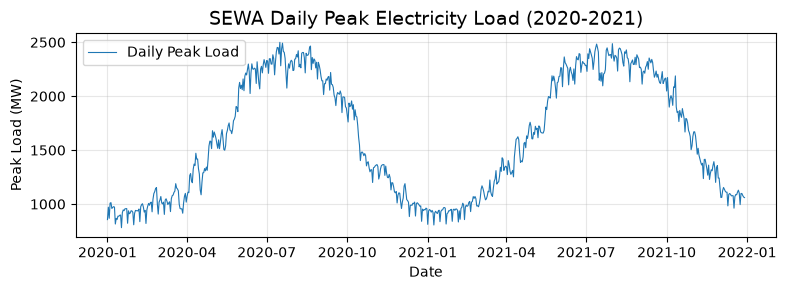

In [64]:
plt.figure(figsize=(8,3))

plt.plot(
  df_final["Date"],
  df_final["SEWA Peak Load(MW)"],
  linewidth=0.8,
  label="Daily Peak Load"
)

plt.title(
  "SEWA Daily Peak Electricity Load (2020-2021)",
  fontsize=14
)

plt.xlabel("Date")
plt.ylabel('Peak Load (MW)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
  "../figures/daily_peak_load_trend.png",
  dpi=300,
  bbox_inches="tight"
)

plt.show()

In [65]:
peak_load = df_final["SEWA Peak Load(MW)"]

print("PEAK LOAD SUMMARY")
print("----------------------")
print("Average:", round(peak_load.mean(), 2), "MW")
print("Median:", round(peak_load.median(), 2), "MW")
print("Menimum:", round(peak_load.min(), 2), "MW")
print("Maximum:", round(peak_load.max(), 2), "MW")
print("Standard deviation:", round(peak_load.std(), 2), "MW")

print("\nDATE OF MAXIMUM PEAK LOAD:")
display(
  df_final.loc[
    peak_load.idxmax(),
    ["Date", "SEWA Peak Load(MW)"]
  ]
)

print("\nDATE OF MINIMUM PEAK LOAD:")
display(
  df_final.loc[
    peak_load.idxmin(),
    ["Date", "SEWA Peak Load(MW)"]
  ]
)


PEAK LOAD SUMMARY
----------------------
Average: 1614.27 MW
Median: 1547.0 MW
Menimum: 781.0 MW
Maximum: 2499.0 MW
Standard deviation: 545.13 MW

DATE OF MAXIMUM PEAK LOAD:


Date                  2020-07-16 00:00:00
SEWA Peak Load(MW)                 2499.0
Name: 197, dtype: object


DATE OF MINIMUM PEAK LOAD:


Date                  2020-01-17 00:00:00
SEWA Peak Load(MW)                  781.0
Name: 16, dtype: object

### 3.3 Monthly Average Peak Electricity Demand

In [66]:
# Extracted year and month from the Date column

df_final["Year"] = df_final["Date"].dt.year
df_final["Month"] = df_final["Date"].dt.month

monthly_demand = (
  df_final.groupby(["Year", "Month"])["SEWA Peak Load(MW)"]
  .mean()
  .reset_index()
) 

# Display monthly demand
display(monthly_demand.round(2))

,Year,Month,SEWA Peak Load(MW)
0,2020,1,914.52
1,2020,2,981.07
2,2020,3,1036.52
3,2020,4,1327.33
4,2020,5,1695.00
5,2020,6,2205.13
6,2020,7,2331.61
7,2020,8,2334.03
8,2020,9,2054.47
9,2020,10,1593.68


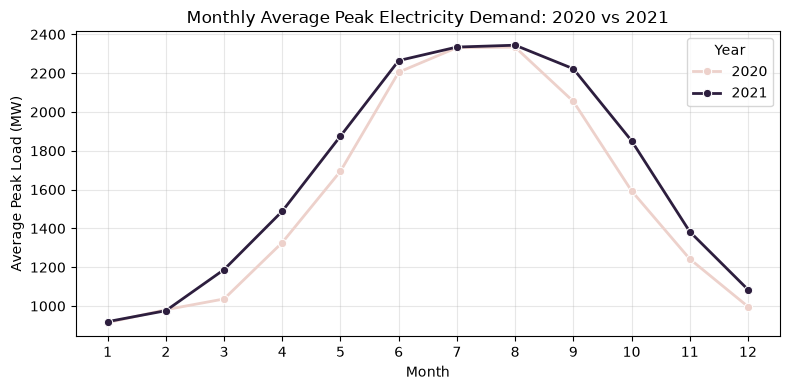

In [67]:
plt.figure(figsize=(8, 4))

sns.lineplot(
  data=monthly_demand,
  x="Month",
  y="SEWA Peak Load(MW)",
  hue="Year",
  marker="o",
  linewidth=2
)

plt.title("Monthly Average Peak Electricity Demand: 2020 vs 2021")
plt.xlabel("Month")
plt.ylabel("Average Peak Load (MW)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(title="Year")
plt.tight_layout()

plt.savefig(
  "../figures/monthly_average_peak_load.png",
  dpi=300,
  bbox_inches="tight"
)

plt.show()

### 3.4 Day-of-Week Average Peak Electricity Demand

In [68]:
df_final["Day_of_Week"] = df_final["Date"].dt.day_name

weekday_order = [
  "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
  df_final.groupby("Day_of_Week")["SEWA Peak Load(MW)"]
  .mean()
  .reindex(weekday_order)
  .reset_index()
)

display(weekday_demand.round(2))

,Day_of_Week,SEWA Peak Load(MW)
0,Monday,NaN
1,Tuesday,NaN
2,Wednesday,NaN
3,Thursday,NaN
4,Friday,NaN
5,Saturday,NaN
6,Sunday,NaN


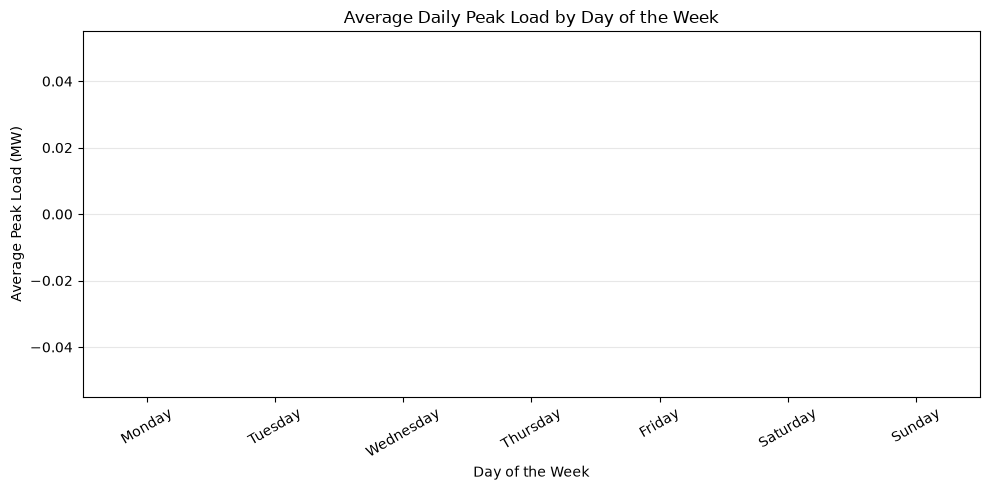

In [69]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_demand,
    x="Day_of_Week",
    y="SEWA Peak Load(MW)"
)

plt.title("Average Daily Peak Load by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Peak Load (MW)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/weekday_average_peak_load.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [70]:

# Confirm that Date is in datetime format
df_final["Date"] = pd.to_datetime(df_final["Date"], errors="coerce")

# Create the weekday column
df_final["Day_of_Week"] = df_final["Date"].dt.day_name()

# Check the weekday values
print("Missing dates:", df_final["Date"].isna().sum())
print("\nWeekday distribution:")
print(df_final["Day_of_Week"].value_counts(dropna=False))

# Calculate average peak load for each weekday
weekday_demand = (
    df_final.groupby("Day_of_Week")["SEWA Peak Load(MW)"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
    .reset_index()
)

display(weekday_demand.round(2))


Missing dates: 0

Weekday distribution:
Day_of_Week
Wednesday    105
Thursday     104
Friday       104
Saturday     104
Sunday       104
Monday       104
Tuesday      104
Name: count, dtype: int64


,Day_of_Week,SEWA Peak Load(MW)
0,Monday,1632.48
1,Tuesday,1624.74
2,Wednesday,1619.43
3,Thursday,1623.35
4,Friday,1526.46
5,Saturday,1632.39
6,Sunday,1641.00


Correlation of weather variables with peak load:


,SEWA Peak Load(MW)
Temp,0.954
Min Tem,0.937
MAX Tem,0.911
Hum,0.122
Max Hum,-0.245
Min Hum,-0.324


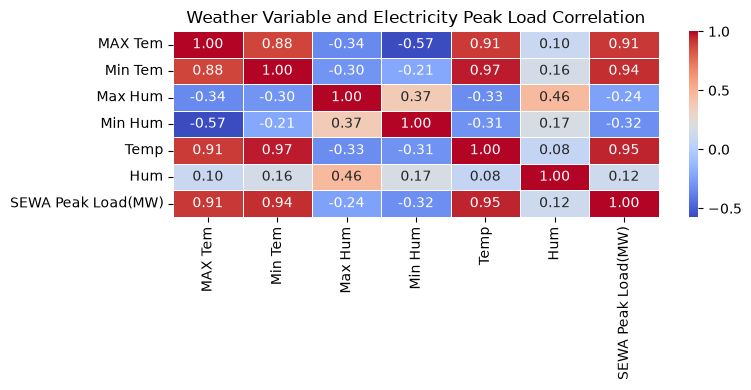

In [71]:
weather_columns = [
 "MAX Tem",
 "Min Tem",
 "Max Hum",
 "Min Hum",
 "Temp",
 "Hum",
 "SEWA Peak Load(MW)"
]

weather_corr = df_final[weather_columns].corr()

peak_load_corr = (
  weather_corr["SEWA Peak Load(MW)"]
  .drop("SEWA Peak Load(MW)")
  .sort_values(ascending=False)
)

print("Correlation of weather variables with peak load:")
display(peak_load_corr.round(3).to_frame())

plt.figure(figsize=(8, 4))

sns.heatmap(
  weather_corr,
  annot=True,
  cmap="coolwarm",
  fmt=".2f",
  linewidths=0.5
)

plt.title("Weather Variable and Electricity Peak Load Correlation")
plt.tight_layout()

plt.savefig(
  "../figures/weather_peak_load_correlation.png",
  dpi=300,
  bbox_inches="tight"
)

plt.show()

In [72]:
df_model = df_final.copy()

df_model["Year"] = df_model["Date"].dt.year
df_model["Month"] = df_model["Date"].dt.month
df_model["Day"] = df_model["Date"].dt.day

df_model["Day_of_Week"] = df_model["Date"].dt.day_name()

df_model["Day_of_Week_Num"] = df_model["Date"].dt.dayofweek

df_model["Is_Weekend"] = (
  df_model["Day_of_Week_Num"].isin([5, 6]).astype(int)
)

# Inspect the new features

display(
  df_model[
    [
      "Date",
      "Year",
      "Month",
      "Day",
      "Day_of_Week",
      "Day_of_Week_Num",
      "Is_Weekend"
    ]
  ].head(10)
) 

,Date,Year,Month,Day,Day_of_Week,Day_of_Week_Num,Is_Weekend
0,2020-01-01,2020,1,1,Wednesday,2,0
1,2020-01-02,2020,1,2,Thursday,3,0
2,2020-01-03,2020,1,3,Friday,4,0
3,2020-01-04,2020,1,4,Saturday,5,1
4,2020-01-05,2020,1,5,Sunday,6,1
5,2020-01-06,2020,1,6,Monday,0,0
6,2020-01-07,2020,1,7,Tuesday,1,0
7,2020-01-08,2020,1,8,Wednesday,2,0
8,2020-01-09,2020,1,9,Thursday,3,0
9,2020-01-10,2020,1,10,Friday,4,0


In [73]:
# Create calendar features

df_model = df_final.copy()

df_model["Year"] = df_model["Date"].dt.year
df_model["Month"] = df_model["Date"].dt.month
df_model["Day"] = df_model["Date"].dt.day

df_model["Day_of_Week"] = df_model["Date"].dt.day_name()

df_model["Day_of_Week_Num"] = df_model["Date"].dt.dayofweek

df_model["Is_Weekend"] = (
  df_model["Day_of_Week_Num"].isin([5, 6]).astype(int)
)

# Inspect the new features
display(
  df_model[
    [
      "Date",
      "Year",
      "Month",
      "Day",
      "Day_of_Week",
      "Day_of_Week_Num",
      "Is_Weekend"
    ]
  ].head(10)
)

,Date,Year,Month,Day,Day_of_Week,Day_of_Week_Num,Is_Weekend
0,2020-01-01,2020,1,1,Wednesday,2,0
1,2020-01-02,2020,1,2,Thursday,3,0
2,2020-01-03,2020,1,3,Friday,4,0
3,2020-01-04,2020,1,4,Saturday,5,1
4,2020-01-05,2020,1,5,Sunday,6,1
5,2020-01-06,2020,1,6,Monday,0,0
6,2020-01-07,2020,1,7,Tuesday,1,0
7,2020-01-08,2020,1,8,Wednesday,2,0
8,2020-01-09,2020,1,9,Thursday,3,0
9,2020-01-10,2020,1,10,Friday,4,0


In [74]:
print("Dataset shape:", df_model.shape)

print("\nMissing values in calendar features:")
print(
  df_model[
    [
      "Year",
      "Month",
      "Day",
      "Day_of_Week",
      "Day_of_Week_Num",
      "Is_Weekend"
    ]
  ].isnull().sum()
)

print("\nWeekend distribution:")
print(df_model["Is_Weekend"].value_counts())

Dataset shape: (729, 14)

Missing values in calendar features:
Year               0
Month              0
Day                0
Day_of_Week        0
Day_of_Week_Num    0
Is_Weekend         0
dtype: int64

Weekend distribution:
Is_Weekend
0    521
1    208
Name: count, dtype: int64


### 4.4 Historical Demand Features

I created the Historical demand features from previous electricity peak-load observations. They help the machine-learning model identify patterns in electricity demand over time. This project uses the previous day's peak load and the average peak load of the previous seven days.

In [75]:
# Previous Day's peak electricity load
df_model["Peak_Load_Lag_1"] = (
  df_model["SEWA Peak Load(MW)"].shift(1)

)

# Average peak load over the previous seven days
df_model["Peak_Load_Rolling_7"] = (
  df_model["SEWA Peak Load(MW)"]
  .shift(1)
  .rolling(window=7)
  .mean()
)

# Inspect the new historical features
display(
  df_model[
    [
      "Date",
      "SEWA Peak Load(MW)",
      "Peak_Load_Lag_1",
      "Peak_Load_Rolling_7"
    ]
  ].head(12)
)

,Date,SEWA Peak Load(MW),Peak_Load_Lag_1,Peak_Load_Rolling_7
0,2020-01-01,856.0,NaN,NaN
1,2020-01-02,971.0,856.0,NaN
2,2020-01-03,868.0,971.0,NaN
3,2020-01-04,1009.0,868.0,NaN
4,2020-01-05,1013.0,1009.0,NaN
5,2020-01-06,959.0,1013.0,NaN
6,2020-01-07,969.0,959.0,NaN
7,2020-01-08,976.0,969.0,949.285714
8,2020-01-09,972.0,976.0,966.428571
9,2020-01-10,815.0,972.0,966.571429


### 4.5 Weather Features

I included Weather features because temperature and humidity conditions may influence electricity demand. This section checks the completeness of the weather variables before they are used for model training.

In [76]:
# Weather Columns
weather_columns = [
  "MAX Tem",
  "Min Tem",
  "Max Hum",
  "Min Hum",
  "Temp",
  "Hum"
]

# Check for missing values
print("Missing values in weather features:")
print(df_model[weather_columns].isnull().sum())

# Data types
print("\nWeather feature data types:")
print(df_model[weather_columns].dtypes)

Missing values in weather features:
MAX Tem    1
Min Tem    1
Max Hum    2
Min Hum    1
Temp       0
Hum        1
dtype: int64

Weather feature data types:
MAX Tem    float64
Min Tem    float64
Max Hum    float64
Min Hum    float64
Temp       float64
Hum        float64
dtype: object


In [77]:
missing_weather = df_model.loc[
  df_model[weather_columns].isnull().any(axis=1),
  ["Date"] + weather_columns
]

display(missing_weather)
print("Number of affected records:", len(missing_weather))

,Date,MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum
496,2021-05-11,34.3,22.5,NaN,25.0,27.1,59.8
552,2021-07-06,44.0,33.0,68.0,26.0,31.0,NaN
728,2021-12-29,NaN,NaN,NaN,NaN,20.0,53.0


Number of affected records: 3


### 4.5.2 Investigating Missing Weather Records

In this section, I investigated whether records with missing weather observations also have missing electricity peak-load measurements. The objective is to determine whether these records can remain useful for forecasting.

In [78]:
# Peak load on dates with missing weather data

display(
  df_model.loc[
    missing_weather.index,
    ["Date", "SEWA Peak Load(MW)"] + weather_columns
  ]
) 

,Date,SEWA Peak Load(MW),MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum
496,2021-05-11,1661.0,34.3,22.5,NaN,25.0,27.1,59.8
552,2021-07-06,2412.0,44.0,33.0,68.0,26.0,31.0,NaN
728,2021-12-29,1060.0,NaN,NaN,NaN,NaN,20.0,53.0


In [79]:
print("Missing values in target:")
print(df_model["SEWA Peak Load(MW)"].isnull().sum())

print("\nTotal records:")
print(len(df_model))

Missing values in target:
0

Total records:
729


In [80]:
print("Missing values in each column:\n")
print(df_model.isnull().sum())

print("\nDataset shape:")
print(df_model.shape)

Missing values in each column:

Date                   0
MAX Tem                1
Min Tem                1
Max Hum                2
Min Hum                1
Temp                   0
Hum                    1
SEWA Peak Load(MW)     0
Year                   0
Month                  0
Day_of_Week            0
Day                    0
Day_of_Week_Num        0
Is_Weekend             0
Peak_Load_Lag_1        1
Peak_Load_Rolling_7    7
dtype: int64

Dataset shape:
(729, 16)


In [81]:
missing_rows = df_model[
  df_model.isnull().any(axis=1)
]

display(missing_rows[
  [
    "Date",
    "SEWA Peak Load(MW)",
    "MAX Tem",
    "Min Tem",
    "Max Hum",
    "Min Hum",
    "Temp",
    "Hum",
    "Peak_Load_Lag_1",
    "Peak_Load_Rolling_7"
  ]
])

,Date,SEWA Peak Load(MW),MAX Tem,Min Tem,Max Hum,Min Hum,Temp,Hum,Peak_Load_Lag_1,Peak_Load_Rolling_7
0,2020-01-01,856.0,27.0,17.0,94.0,45.0,18.7,57.1,NaN,NaN
1,2020-01-02,971.0,27.0,16.0,90.0,45.0,20.0,36.0,856.0,NaN
2,2020-01-03,868.0,28.0,15.0,91.0,34.0,20.0,56.8,971.0,NaN
3,2020-01-04,1009.0,30.0,15.0,80.0,23.0,20.0,33.0,868.0,NaN
4,2020-01-05,1013.0,29.0,16.5,67.0,32.0,21.0,26.0,1009.0,NaN
5,2020-01-06,959.0,24.0,12.0,81.0,32.0,22.0,47.0,1013.0,NaN
6,2020-01-07,969.0,24.4,11.5,84.0,31.0,18.0,34.0,959.0,NaN
496,2021-05-11,1661.0,34.3,22.5,NaN,25.0,27.1,59.8,1669.0,1691.285714
552,2021-07-06,2412.0,44.0,33.0,68.0,26.0,31.0,NaN,2440.0,2326.857143
728,2021-12-29,1060.0,NaN,NaN,NaN,NaN,20.0,53.0,1065.0,1080.857143


In [82]:
# The target variable

target = "SEWA Peak Load(MW)"

# Input features
features = [
  "MAX Tem",
  "Min Tem",
  "Max Hum",
  "Min Hum",
  "Temp",
  "Hum",
  "Year",
  "Month",
  "Day_of_Week_Num",
  "Is_Weekend",
  "Peak_Load_Lag_1",
  "Peak_Load_Rolling_7"

]

# Create x and y
x = df_model[features].copy()
y = df_model[target].copy()

print("Input features shape:", x.shape)
print("Target shape:", y.shape)

print("\nInput feature columns:")
print(x.columns.tolist())

Input features shape: (729, 12)
Target shape: (729,)

Input feature columns:
['MAX Tem', 'Min Tem', 'Max Hum', 'Min Hum', 'Temp', 'Hum', 'Year', 'Month', 'Day_of_Week_Num', 'Is_Weekend', 'Peak_Load_Lag_1', 'Peak_Load_Rolling_7']


In [83]:
df_model = df_model.sort_values("Date").reset_index(drop=True)

# Remove the first seven rcords with incomplete historical features
model_data = df_model.iloc[7:].copy()

# Calculate the 80% training boundary
split_index = int(len(model_data) * 0.8)

# Split chronologically
train_data = model_data.iloc[:split_index].copy()
test_data = model_data.iloc[split_index:].copy()

# Separate input features and target
x_train = train_data[features]
y_train = train_data[target]

x_test = test_data[features]
y_test = test_data[target]

# Display results
print("Total modelling records:", len(model_data))
print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining date range:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting date range:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Total modelling records: 722
Training records: 577
Testing records: 145

Training date range:
2020-01-08 00:00:00 to 2021-08-06 00:00:00

Testing date range:
2021-08-07 00:00:00 to 2021-12-29 00:00:00


In [84]:
# Baseline preedictions using previous day's peak load
y_pred_baseline = x_test["Peak_Load_Lag_1"]

# Display actual and predicited values
baseline_results = pd.DataFrame({
  "Actual Peak Load (MW)": y_test,
  "Predicted Peak Load (MW)": y_pred_baseline
})

display(baseline_results.head(10))  

,Actual Peak Load (MW),Predicted Peak Load (MW)
584,2429.0,2233.0
585,2446.0,2429.0
586,2441.0,2446.0
587,2416.0,2441.0
588,2386.0,2416.0
589,2313.0,2386.0
590,2279.0,2313.0
591,2411.0,2279.0
592,2398.0,2411.0
593,2429.0,2398.0


In [85]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)

baseline_rmse = np.sqrt(
  mean_squared_error(y_test, y_pred_baseline)
)

baseline_r2 = r2_score(y_test, y_pred_baseline)

print("BASELINE MODEL PERFORMANCE")
print("---------------------------")
print("MAE:", round(baseline_mae, 2), "MW")
print("RMSE:", round(baseline_rmse, 2), "MW")
print("R2:", round(baseline_r2, 4))

BASELINE MODEL PERFORMANCE
---------------------------
MAE: 56.35 MW
RMSE: 75.24 MW
R2: 0.9761


In [86]:
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [87]:
linear_model = make_pipeline(
  SimpleImputer(strategy="median"),
  StandardScaler(),
  LinearRegression()
)

linear_model.fit(x_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [88]:
y_pred_linear = linear_model.predict(x_test)

linear_mae = mean_absolute_error(y_test, y_pred_linear)

linear_rmse = np.sqrt(
  mean_squared_error(y_test, y_pred_linear)
)

linear_r2 = r2_score(y_test, y_pred_linear)

print("LINEAR REGRESSION PERFORMAANCE")
print("-------------------------------")
print("MAAE:", round(linear_mae, 2), "MW")
print("RMSE:", round(linear_rmse, 2), "MW")
print("R2:", round(linear_r2, 4))

LINEAR REGRESSION PERFORMAANCE
-------------------------------
MAAE: 42.53 MW
RMSE: 55.09 MW
R2: 0.9872


In [89]:
from sklearn.ensemble import RandomForestRegressor

In [90]:
rf_model = make_pipeline(
  SimpleImputer(strategy="median"),
  RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
  )
)

rf_model.fit(x_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [91]:
y_pred_rf = rf_model.predict(x_test)

rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(
  mean_squared_error(y_test, y_pred_rf)
)

rf_r2 = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST PERFORMAAANCE")
print("----------------------------")
print("MAE:", round(rf_mae, 2), "MW")
print("RMSE:", round(rf_rmse, 2), "MW")
print("R2:", round(rf_r2, 44))


RANDOM FOREST PERFORMAAANCE
----------------------------
MAE: 49.99 MW
RMSE: 62.78 MW
R2: 0.983388473325181


In [92]:
# Create model Performance comparison

model_comparison = pd.DataFrame({
  "Model": [
    "Baseline",
    "Linear Regression",
    "Random Forest"
  ],
  "MAE": [
    baseline_mae,
    linear_mae,
    rf_mae
  ], 
  "RMSE": [
    baseline_rmse,
    linear_rmse,
    rf_rmse
  ],
  "R2": [
    baseline_r2,
    linear_r2,
    rf_r2
  ]
})

model_comparison = model_comparison.round(4)

display(model_comparison)

,Model,MAE,RMSE,R2
0,Baseline,56.3517,75.2357,0.9761
1,Linear Regression,42.5260,55.0897,0.9872
2,Random Forest,49.9932,62.7815,0.9834


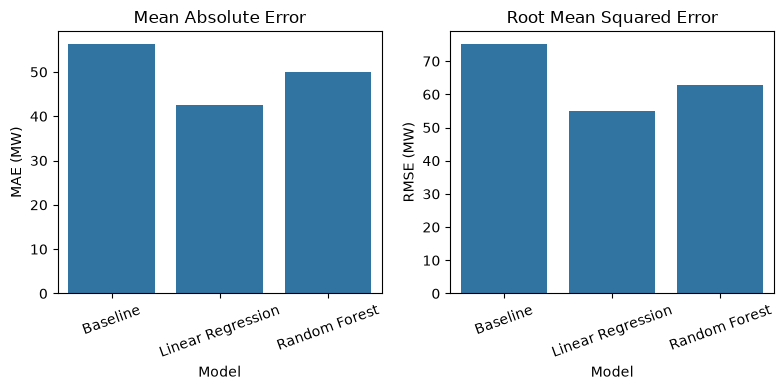

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sns.barplot(
  data=model_comparison,
  x="Model",
  y="MAE",
  ax=axes[0]
)

axes[0].set_title("Mean Absolute Error")
axes[0].set_ylabel("MAE (MW)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
  data=model_comparison,
  x="Model",
  y="RMSE",
  ax=axes[1]
)

axes[1].set_title("Root Mean Squared Error")
axes[1].set_ylabel("RMSE (MW)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()

plt.savefig(
  "../figures/model_performance_comparison.png",
  dpi=300,
  bbox_inches="tight"
)

plt.show()

In [95]:
import pandas as pd
import os
import joblib

# Extract coeficients from the trained Linear Regression pipline
coefficients = linear_model.named_steps["linearregression"].coef_

# Feature coefficient table
coefficient_table = pd.DataFrame({
  "Feature": features,
  "Coefficient": coefficients
})

coefficient_table["Absolute_Coefficient"] = (
  coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
  by="Absolute_Coefficient",
  ascending=False
)

display(coefficient_table)

,Feature,Coefficient,Absolute_Coefficient
10,Peak_Load_Lag_1,343.025182,343.025182
11,Peak_Load_Rolling_7,126.728021,126.728021
0,MAX Tem,95.368143,95.368143
9,Is_Weekend,58.876747,58.876747
8,Day_of_Week_Num,-43.616071,43.616071
3,Min Hum,22.159549,22.159549
4,Temp,21.449009,21.449009
7,Month,-15.572566,15.572566
1,Min Tem,-15.218670,15.218670
6,Year,3.498974,3.498974


In [96]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
  linear_model,
  "../models/sewa_linear_regression.joblib"
)

print("Best-performing model saved succefully")

Best-performing model saved succefully
